# Lab 5: Logistic Regression and Classification Evaluation
## Al-Farabi Kazakh National University, Kazakhstan
**Level:** Master's students · **Language:** English · **Suggested duration:** 3 hours plus independent challenges

**Student:** Omarkhaliyeva Nazerke
**Student ID / group:** IS
**Date:** 14.11.2026

This lab follows Lecture 5: classification, sigmoid probabilities, logistic regression, confusion matrices, precision, recall, F1 and threshold selection. The master's extensions cover regularisation, calibration, statistical uncertainty and distribution shift.

The main case is **synthetic payment-risk screening**. Class 1 represents a simulated suspicious payment. These data do not describe real people, a bank or Kazakhstan's financial system. A second, optional dataset uses the built-in Iris measurements for multiclass classification.

**Deliverable:** Submit this completed `.ipynb` with executed outputs, written interpretations and your conclusion. Keep this notebook in English or write your responses in the language agreed with your instructor. Suggested filename: `StudentID_Lab5_Classification.ipynb`.

## Learning outcomes and assessment
By completing the lab, you should be able to:
- Build a reproducible classification pipeline with independent training, validation and test partitions.
- Calculate metrics from confusion-matrix counts and explain the cost of different mistakes.
- Select a threshold using validation data and evaluate a frozen decision rule on the test set.
- Interpret coefficients as conditional associations, with appropriate limits.
- Investigate regularisation, probability calibration and uncertainty.

| Component | Marks |
|---|---:|
| A. Problem definition and exploratory analysis | 10 |
| B. Splitting, preprocessing and baseline | 15 |
| C. Manual metrics and probability reasoning | 15 |
| D. Validation comparison and threshold selection | 20 |
| E. Final evaluation and interpretation | 15 |
| F. One master's challenge and critical discussion | 20 |
| Reproducibility and presentation | 5 |
| **Total** | **100** |

**Working rules:** Decide preprocessing and models using training data. Use validation data for selection. Access the test results only after freezing the model and threshold. Do not select the best random seed. Record unsuccessful experiments as well as successful ones.

Cells marked **DEMONSTRATION** provide working examples. Cells marked **STUDENT TASK** contain `None`, `TODO`, or a written-response space. The notebook runs before completion and reports pending tasks rather than pretending they are finished. Expected results describe properties, not target scores.

## Setup
The notebook requires Python 3.10+ and `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`. No dataset download is required. In your own environment, install missing packages with `%pip install numpy pandas matplotlib scipy scikit-learn`, then restart the kernel.

### Cell 1 — DEMONSTRATION: imports and reproducibility
This cell imports the analysis tools, fixes a reproducible seed and prints package versions. The seed makes experiments repeatable, but does not eliminate sampling uncertainty.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.special import expit
from sklearn.base import clone
from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    classification_report, precision_recall_curve)
from sklearn.calibration import calibration_curve
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns', 15)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6 | pandas: 2.2.3 | sklearn: 1.6.1


## A. Problem definition and data (10 marks)
**Scenario:** An analyst must rank payments for investigation. Missing suspicious payments has a cost, while reviewing genuine payments consumes staff time. We investigate those competing costs using simulated labels.

### Cell 2 — DEMONSTRATION: construct the offline dataset
`make_classification` produces 6,000 observations and 12 continuous features, with a minority positive class. Feature names are deliberately neutral because the generator does not create real economic measurements. Missing values are injected independently of the target to exercise preprocessing. The generator's `class_sep` and `flip_y` control simulation difficulty, not real-world reliability.

In [2]:
X_array, y_array = make_classification(
    n_samples=6000, n_features=12, n_informative=7, n_redundant=3,
    n_repeated=0, n_clusters_per_class=2, weights=[0.97, 0.03],
    class_sep=1.3, flip_y=0.005, random_state=SEED)
feature_names = [f'signal_{i:02d}' for i in range(1, 13)]
X = pd.DataFrame(X_array, columns=feature_names)
y = pd.Series(y_array, name='suspicious_payment')
rng = np.random.default_rng(SEED)
X = X.mask(rng.random(X.shape) < 0.025)
print('Feature matrix:', X.shape)
print('Target coding: 0 = simulated genuine, 1 = simulated suspicious')

Feature matrix: (6000, 12)
Target coding: 0 = simulated genuine, 1 = simulated suspicious


### Task A1 — written problem statement (4 marks)
Complete the response below **before fitting models**. Define the unit of observation, features, target and positive class. Explain a false positive and a false negative in this scenario. Which mistake would you initially prioritise, and why?

**My response:**

One row in this lab is one simulated payment. The 12 columns named `signal_01` to `signal_12` are the features. They are numbers that may help the model make a prediction. The target is `suspicious_payment`. Class 0 means a genuine payment and class 1 means a suspicious payment. We want to predict class 1.

A false positive means that the model marks a genuine payment as suspicious. This means a worker may spend time checking a normal payment. A false negative means that the model misses a suspicious payment. I would focus more on false negatives at first because missing a suspicious payment may be more serious. However, we should not ignore false positives because too many alerts can waste time. The data are artificial, so these risks are only examples for this lab.

### Cell 3 — DEMONSTRATION: split before exploration
Create a 60% training, 20% validation and 20% test partition, stratified by class. All rows are independent synthetic transactions. For real repeated customers, scanners or time series, random row splitting may be inappropriate. We print training and validation summaries and keep test labels out of exploration.

In [3]:
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_remaining, y_remaining, test_size=0.50, stratify=y_remaining, random_state=SEED)
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)
print('Rows:', len(X_train), 'train,', len(X_valid), 'validation,', len(X_test), 'test')
print(pd.DataFrame({'training': y_train.value_counts(), 'validation': y_valid.value_counts()}))
print('Training positive prevalence:', round(y_train.mean(), 4))

Rows: 3600 train, 1200 validation, 1200 test
                    training  validation
suspicious_payment                      
0                       3483        1161
1                        117          39
Training positive prevalence: 0.0325


### Cell 4 — STUDENT TASK A2: training-only exploration (6 marks)
Complete the missing expressions. Calculate missing-value percentages, plot class frequencies and compare one feature across training classes. Explain why accuracy alone is likely to mislead.

**Hints:** use `isna().mean() * 100`, `value_counts()` and a boxplot or overlaid histogram. Use `X_train` and `y_train`, not the complete data.

signal_06    2.722222
signal_12    2.666667
signal_10    2.638889
signal_05    2.555556
signal_02    2.527778
signal_11    2.500000
signal_01    2.472222
signal_08    2.472222
signal_09    2.472222
signal_03    2.444444
signal_04    2.333333
signal_07    2.222222
dtype: float64


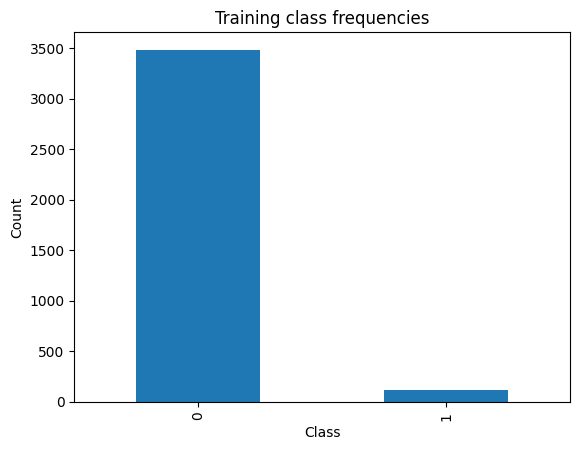

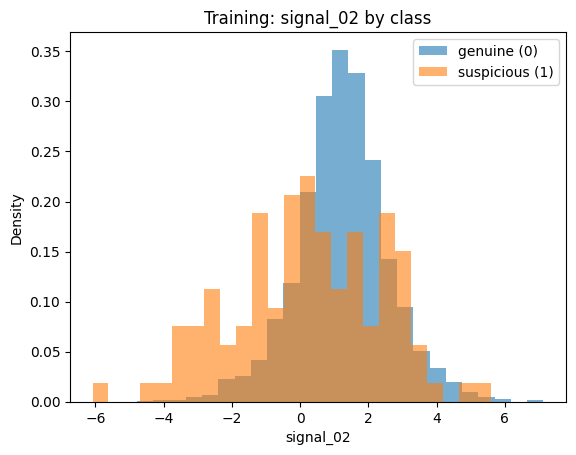

In [4]:
missing_percent = X_train.isna().mean() * 100  # missing values in training (%)
training_class_counts = y_train.value_counts()  # number of rows in each class
if missing_percent is None or training_class_counts is None:
    print('TASK A2 pending: complete both expressions and add your plots.')
else:
    print(missing_percent.sort_values(ascending=False))
    training_class_counts.sort_index().plot.bar(title='Training class frequencies')
    plt.xlabel('Class'); plt.ylabel('Count'); plt.show()
# Compare the same feature for both classes (training data only).
feature = 'signal_02'
plt.hist(X_train.loc[y_train == 0, feature].dropna(), bins=25,
         density=True, alpha=0.6, label='genuine (0)')
plt.hist(X_train.loc[y_train == 1, feature].dropna(), bins=25,
         density=True, alpha=0.6, label='suspicious (1)')
plt.xlabel(feature)
plt.ylabel('Density')
plt.title('Training: signal_02 by class')
plt.legend()
plt.show()

**A2 interpretation:**

The training data have 3,483 genuine payments but only 117 suspicious payments. So only about 3.25% belong to class 1. Each feature has around 2–3% missing values. In the histogram of `signal_02`, the two classes have different distributions, although they also overlap. This feature might help with prediction, but we cannot say it causes suspicious payments. The numbers are generated by a computer, and other features can also affect the model. Accuracy alone can be misleading: a model predicting only class 0 already gets 96.75% accuracy but misses all suspicious payments.

## B. Pipeline and baseline (15 marks)
### Cell 5 — DEMONSTRATION: preprocessing inside a pipeline
The imputer learns medians from training rows. The scaler learns training means and standard deviations. The classifier fits regularised logistic regression. Calling `predict_proba` later applies those same fitted transformations to new rows. Imputation and scaling are not refitted on validation or test data.

In [5]:
def make_pipeline(C=1.0, class_weight=None):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LogisticRegression(C=C, class_weight=class_weight,
                                     max_iter=3000, solver='lbfgs', random_state=SEED))])
model_plain = make_pipeline()
model_plain.fit(X_train, y_train)
p_valid_plain = model_plain.predict_proba(X_valid)[:, 1]
print('Classes:', model_plain.named_steps['model'].classes_)
print('First five validation positive-class probabilities:', p_valid_plain[:5])

Classes: [0 1]
First five validation positive-class probabilities: [0.0438 0.0001 0.0055 0.042  0.0077]


### Cell 6 — DEMONSTRATION: majority-class baseline
A baseline gives context. This classifier always predicts the most frequent training class. A high accuracy with zero positive recall is possible on an imbalanced dataset. The helper function reports threshold-dependent metrics alongside score-based discrimination. Average precision summarises the PR curve; we name it explicitly rather than implying all PR-area conventions are identical.

In [6]:
def metric_row(y_true, probability, threshold=0.5):
    prediction = (np.asarray(probability) >= threshold).astype(int)
    return {'accuracy': accuracy_score(y_true, prediction),
            'balanced_accuracy': balanced_accuracy_score(y_true, prediction),
            'precision': precision_score(y_true, prediction, zero_division=0),
            'recall': recall_score(y_true, prediction, zero_division=0),
            'F1': f1_score(y_true, prediction, zero_division=0),
            'ROC_AUC': roc_auc_score(y_true, probability),
            'average_precision': average_precision_score(y_true, probability)}
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
p_valid_baseline = baseline.predict_proba(X_valid)[:, 1]
comparison_initial = pd.DataFrame({
    'majority_baseline': metric_row(y_valid, p_valid_baseline),
    'logistic_default': metric_row(y_valid, p_valid_plain)}).T
print(comparison_initial.round(4))

                   accuracy  balanced_accuracy  precision  recall      F1  \
majority_baseline    0.9675             0.5000     0.0000  0.0000  0.0000   
logistic_default     0.9792             0.6919     0.9375  0.3846  0.5455   

                   ROC_AUC  average_precision  
majority_baseline   0.5000             0.0325  
logistic_default    0.8748             0.5764  


### Task B1 — pipeline audit (15 marks)
Answer all three questions:
1. Why would fitting the imputer or scaler on the full dataset constitute leakage?
2. Why might a randomly split real payment dataset leak information even when preprocessing uses a pipeline? Give a customer-group or time example.
3. Compare the baseline and model using at least three reported metrics. Explain which result would matter to investigators.

**My response:**

1. If we calculate missing-value medians or scaling values on the whole dataset, information from validation and test rows enters training. This is data leakage. In our pipeline, the imputer and scaler learn only from training data.
2. In a real payment dataset, the same customer might have many payments. If their payments are in both training and test sets, the model can learn that customer's patterns instead of learning something general. Also, using future payments to predict earlier payments would be a time leak. Group or time splits could be better.
3. The majority baseline has 96.75% accuracy, but its recall, precision and F1 are all zero. Logistic regression at threshold 0.5 has 97.92% accuracy, 38.46% recall and 54.55% F1. Its ROC-AUC is about 0.875, compared with 0.5 for the baseline. For investigators, recall matters because it shows how many suspicious payments the system finds. Precision also matters because low precision means extra checks.

## C. Probabilities and manual evaluation (15 marks)
### Cell 7 — DEMONSTRATION: sigmoid and threshold
The sigmoid converts a real-valued score into a probability estimate. Thresholding produces a decision. An estimated probability of 0.9 does not guarantee 90% correctness unless calibration and the deployment population support that interpretation.

   score  probability  decision_at_0.5
0   -4.0     0.017986                0
1   -2.0     0.119203                0
2    0.0     0.500000                1
3    2.0     0.880797                1
4    4.0     0.982014                1


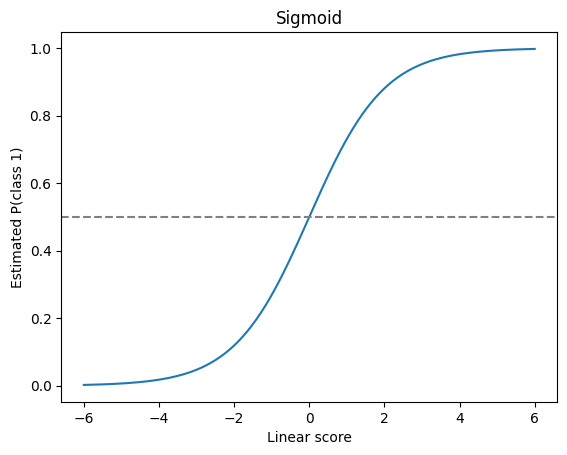

In [7]:
scores = np.array([-4.0, -2.0, 0.0, 2.0, 4.0])
print(pd.DataFrame({'score': scores, 'probability': expit(scores),
                    'decision_at_0.5': (expit(scores) >= 0.5).astype(int)}))
z = np.linspace(-6, 6, 200)
plt.plot(z, expit(z)); plt.axhline(0.5, color='grey', linestyle='--')
plt.xlabel('Linear score'); plt.ylabel('Estimated P(class 1)'); plt.title('Sigmoid')
plt.show()

### Cell 8 — STUDENT TASK C1: compute metrics from scratch (10 marks)
For 1,000 payments, use TN = 960, FP = 20, FN = 5 and TP = 15, matching the lecture exercise. Implement the four formulas without calling scikit-learn. Return zero when a denominator is zero. Then implement a general function accepting these four counts.

**Expected:** accuracy is lower than the 98% majority baseline, despite useful positive detection. F1 should lie between precision and recall.

In [8]:
def safe_ratio(numerator, denominator):
    return numerator / denominator if denominator else 0.0

def manual_metrics(tn, fp, fn, tp):
    # These four formulas use only the confusion-matrix counts.
    accuracy = safe_ratio(tp + tn, tp + tn + fp + fn)
    precision = safe_ratio(tp, tp + fp)
    recall = safe_ratio(tp, tp + fn)
    f1 = safe_ratio(2 * precision * recall, precision + recall)
    return {'accuracy': accuracy, 'precision': precision, 'recall': recall, 'F1': f1}

manual_result = manual_metrics(tn=960, fp=20, fn=5, tp=15)
if any(v is None for v in manual_result.values()):
    print('TASK C1 pending:', manual_result)
else:
    print(manual_result)
    reference_y = np.array([0]*980 + [1]*20)
    reference_prediction = np.array([0]*960 + [1]*20 + [0]*5 + [1]*15)
    reference = [accuracy_score(reference_y, reference_prediction),
                 precision_score(reference_y, reference_prediction),
                 recall_score(reference_y, reference_prediction),
                 f1_score(reference_y, reference_prediction)]
    assert np.allclose(list(manual_result.values()), reference), 'Check denominators and cell meanings.'
    print('CHECK: manual results agree with the independent label-based calculation.')

{'accuracy': 0.975, 'precision': 0.42857142857142855, 'recall': 0.75, 'F1': 0.5454545454545454}
CHECK: manual results agree with the independent label-based calculation.


### Cell 9 — STUDENT TASK C2: verify metrics on model predictions (5 marks)
Use validation predictions at threshold 0.5. Extract TN, FP, FN and TP with `confusion_matrix(..., labels=[0,1]).ravel()`. Pass the counts to your function. Compare its answers with the library values.

**My explanation:** Precision checks how many predicted suspicious payments were really suspicious, so its denominator is TP + FP. Recall checks how many real suspicious payments were found, so its denominator is TP + FN.

Rows = truth, columns = prediction:
 [[1160    1]
 [  24   15]]
sklearn metrics: {'accuracy': 0.9791666666666666, 'precision': 0.9375, 'recall': 0.38461538461538464, 'F1': 0.5454545454545454}
{'accuracy': np.float64(0.9791666666666666), 'precision': np.float64(0.9375), 'recall': np.float64(0.38461538461538464), 'F1': np.float64(0.5454545454545454)}


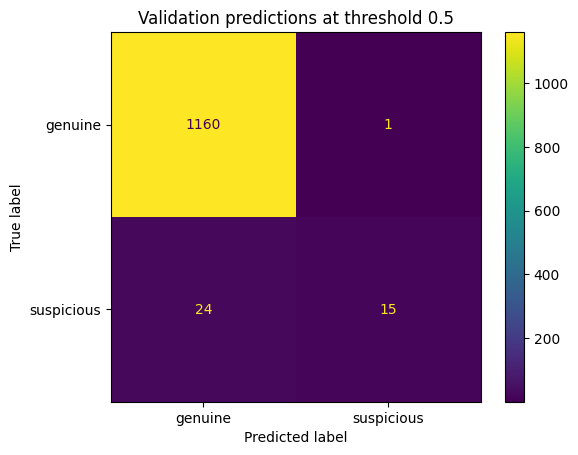

In [9]:
valid_predictions = (p_valid_plain >= 0.5).astype(int)
valid_counts = confusion_matrix(y_valid, valid_predictions, labels=[0, 1])
print('Rows = truth, columns = prediction:\n', valid_counts)
# Use the confusion matrix numbers in our own function.
tn, fp, fn, tp = valid_counts.ravel()
manual_valid = manual_metrics(tn, fp, fn, tp)
print('sklearn metrics:', {key: metric_row(y_valid, p_valid_plain)[key]
                           for key in ['accuracy', 'precision', 'recall', 'F1']})
if manual_valid is None:
    print('TASK C2 pending: unpack valid_counts and calculate manual_valid.')
else:
    print(manual_valid)
ConfusionMatrixDisplay(valid_counts, display_labels=['genuine', 'suspicious']).plot()
plt.title('Validation predictions at threshold 0.5'); plt.show()

## D. Model comparison and threshold selection (20 marks)
### Cell 10 — DEMONSTRATION: compare class weighting
Class weighting changes the fitting objective. It can improve minority recall while worsening precision or probability calibration. We compare both alternatives on validation data and retain the training-only fitted models. No test metrics are calculated here.

In [10]:
model_balanced = make_pipeline(class_weight='balanced')
model_balanced.fit(X_train, y_train)
p_valid_balanced = model_balanced.predict_proba(X_valid)[:, 1]
models = {'plain': model_plain, 'balanced': model_balanced}
valid_probabilities = {'plain': p_valid_plain, 'balanced': p_valid_balanced}
print(pd.DataFrame({name: metric_row(y_valid, p)
                    for name, p in valid_probabilities.items()}).T.round(4))

          accuracy  balanced_accuracy  precision  recall      F1  ROC_AUC  \
plain       0.9792             0.6919     0.9375  0.3846  0.5455   0.8748   
balanced    0.8142             0.8048     0.1260  0.7949  0.2175   0.8906   

          average_precision  
plain                0.5764  
balanced             0.5187  


### Cell 11 — STUDENT TASK D1: select a model and build a threshold table (8 marks)
Set `selected_name` to `plain` or `balanced`, based on validation evidence. For each threshold, compute precision, recall, F1, FP and FN. Assume a missed suspicious payment costs **20 arbitrary units** and a false alarm costs **1 unit**. These are teaching assumptions, not measured financial costs.

Cost = 20 × FN + 1 × FP. Do not add model-training costs to this particular objective. **Hint:** use `metric_row`, `confusion_matrix` and append a dictionary to `rows`.

**Written justification:** I chose the balanced model because, after checking thresholds on validation data, its lowest cost is 298 units. The plain model's lowest validation cost is 309 units. The balanced model can find more positive cases, although it also makes more false alarms. The costs of 20 for FN and 1 for FP are just classroom assumptions. Real costs may be different and should be measured before using a model in practice.

In [11]:
selected_name = 'balanced'  # chosen using validation results
threshold_table = None
if selected_name is None:
    print('TASK D1 pending: choose a model and implement the loop.')
else:
    assert selected_name in models
    p_valid_selected = valid_probabilities[selected_name]
    rows = []
    for threshold in np.linspace(0.01, 0.99, 99):
        measures = metric_row(y_valid, p_valid_selected, threshold)
        predictions = (p_valid_selected >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_valid, predictions, labels=[0, 1]).ravel()
        rows.append({'threshold': round(float(threshold), 2),
                     'precision': measures['precision'],
                     'recall': measures['recall'],
                     'F1': measures['F1'],
                     'FP': fp, 'FN': fn, 'cost': 20 * fn + fp})
    if rows:
        threshold_table = pd.DataFrame(rows)
        print(threshold_table.sort_values('cost').head(10))
    else:
        print('Complete the threshold loop.')

    threshold  precision    recall        F1   FP  FN  cost
64       0.65   0.228346  0.743590  0.349398   98  10   298
66       0.67   0.245614  0.717949  0.366013   86  11   306
63       0.64   0.213235  0.743590  0.331429  107  10   307
59       0.60   0.184049  0.769231  0.297030  133   9   313
65       0.66   0.231405  0.717949  0.350000   93  11   313
62       0.63   0.202797  0.743590  0.318681  114  10   314
58       0.59   0.176471  0.769231  0.287081  140   9   320
61       0.62   0.193333  0.743590  0.306878  121  10   321
57       0.58   0.170455  0.769231  0.279070  146   9   326
60       0.61   0.185897  0.743590  0.297436  127  10   327


### Cell 12 — STUDENT TASK D2: freeze the decision rule (7 marks)
Choose the validation threshold with minimum cost. State a deterministic tie rule, such as selecting the highest threshold among equal-cost solutions. Also identify the validation threshold with maximum F1. Explain why they can differ.

Set `chosen_threshold`, `selection_reason` and `decision_frozen=True` only after your analysis is complete. The final test cell will then run. This workflow is an educational guard, not an access-control mechanism.

**Hint:** sort cost ascending and threshold descending, then select the first row. Do not change the threshold after seeing test performance.

**My explanation:** I pick the threshold with the lowest validation cost. If two thresholds give the same cost, I choose the higher threshold. The best F1 threshold may be different because F1 treats precision and recall together, but our cost calculation makes a missed suspicious payment 20 times more expensive than a false alarm.

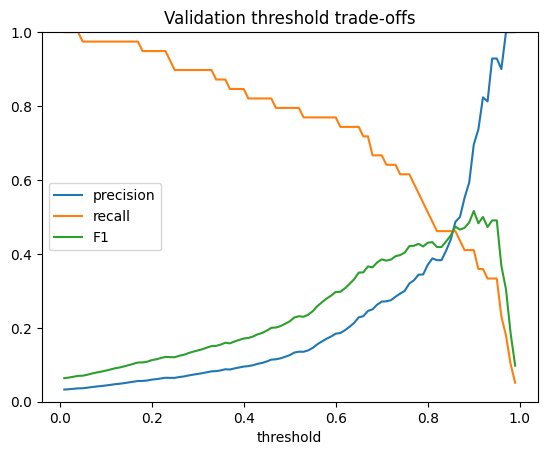

Lowest-cost threshold: 0.65 | cost: 298
Highest-F1 threshold: 0.9 | F1: 0.5161


In [12]:
chosen_threshold = None  # filled from the validation threshold table below
selection_reason = ''  # filled after comparing the validation costs
if threshold_table is not None:
    threshold_table.plot(x='threshold', y=['precision', 'recall', 'F1'], ylim=(0, 1))
    plt.title('Validation threshold trade-offs'); plt.show()
    # First sort by lowest cost, then highest threshold if there is a tie.
    best_cost = threshold_table.sort_values(['cost', 'threshold'],
                                            ascending=[True, False]).iloc[0]
    best_f1 = threshold_table.sort_values(['F1', 'threshold'],
                                          ascending=[False, False]).iloc[0]
    chosen_threshold = float(best_cost['threshold'])
    selection_reason = ('Lowest validation cost (20*FN + FP). '
                        'If costs tie, use the higher threshold.')
    print('Lowest-cost threshold:', chosen_threshold,
          '| cost:', int(best_cost['cost']))
    print('Highest-F1 threshold:', float(best_f1['threshold']),
          '| F1:', round(float(best_f1['F1']), 4))
else:
    print('Finish Task D1 before selecting a threshold.')
decision_frozen = chosen_threshold is not None and bool(selection_reason)  # freeze the rule

### Task D3 — analytical reasoning (5 marks)
1. Explain why lowering a threshold cannot reduce recall on a fixed set of scores, but need not monotonically reduce precision.
2. Does changing the threshold change ROC-AUC? Explain.
3. Why is choosing a threshold on the test set an optimistic evaluation procedure?
4. What happens to PPV if prevalence falls, even with unchanged sensitivity and specificity?

**My response:**

1. When we lower the threshold, we classify the same or more payments as positive. A true positive cannot become a false negative, so recall cannot go down. Precision is less predictable: it depends on whether the extra positive predictions are correct or wrong.
2. Changing the threshold does not change ROC-AUC. ROC-AUC looks at the ranking over all possible thresholds. The predicted probabilities stay the same.
3. If we pick a threshold using the test results, we are using the test data to make a decision. The reported result could then look better than performance on new data.
4. PPV is the same idea as precision. If suspicious payments become less common and sensitivity and specificity stay the same, a smaller share of positive alerts will usually be correct. So PPV becomes lower.

## E. Final test evaluation and interpretation (15 marks)
### Cell 13 — STUDENT TASK E1: one final evaluation (8 marks)
Run this cell after freezing your choice. It evaluates the already fitted model and unchanged threshold. Compare with the default threshold and majority baseline for context, without selecting a new winner from test results. The validation result may not reproduce exactly on the test set.

**Expected:** a complete report, confusion matrix and cost total. A disappointing result is a valid finding. Never adjust the model to improve this test score.

Frozen model: balanced | threshold: 0.65
Selection rationale: Lowest validation cost (20*FN + FP). If costs tie, use the higher threshold.
                              accuracy  balanced_accuracy  precision  recall  \
chosen_rule                     0.8917             0.7953     0.1862  0.6923   
same_model_default_threshold    0.8075             0.8386     0.1308  0.8718   
majority_baseline               0.9675             0.5000     0.0000  0.0000   

                                  F1  ROC_AUC  average_precision  
chosen_rule                   0.2935   0.8627             0.3469  
same_model_default_threshold  0.2274   0.8627             0.3469  
majority_baseline             0.0000   0.5000             0.0325  
              precision    recall  f1-score   support

     genuine       0.99      0.90      0.94      1161
  suspicious       0.19      0.69      0.29        39

    accuracy                           0.89      1200
   macro avg       0.59      0.80      0.62      1200


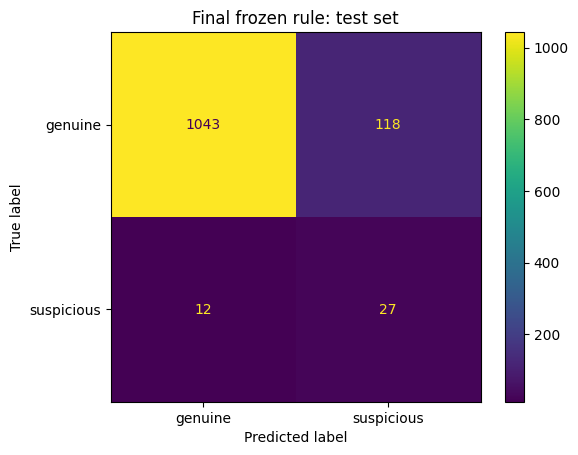

In [13]:
final_results = None
p_test = None
if not decision_frozen or selected_name is None or chosen_threshold is None:
    print('Final test locked: complete model/threshold selection and freeze the decision rule.')
else:
    assert 0 <= chosen_threshold <= 1
    assert selection_reason.strip(), 'Document why you selected this rule.'
    final_model = models[selected_name]
    p_test = final_model.predict_proba(X_test)[:, 1]
    pred_test = (p_test >= chosen_threshold).astype(int)
    final_results = pd.DataFrame({
        'chosen_rule': metric_row(y_test, p_test, chosen_threshold),
        'same_model_default_threshold': metric_row(y_test, p_test, 0.5),
        'majority_baseline': metric_row(y_test, baseline.predict_proba(X_test)[:, 1])}).T
    print('Frozen model:', selected_name, '| threshold:', chosen_threshold)
    print('Selection rationale:', selection_reason)
    print(final_results.round(4))
    print(classification_report(y_test, pred_test, target_names=['genuine', 'suspicious'], zero_division=0))
    tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
    print('Test cost:', 20*fn + fp, 'arbitrary units')
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['genuine', 'suspicious'])
    plt.title('Final frozen rule: test set'); plt.show()

### Cell 14 — DEMONSTRATION: interpret fitted coefficients
For standardised features, `exp(coefficient)` describes the conditional odds multiplier for a one-training-standard-deviation increase, holding other model inputs fixed. Correlated features, imputation and regularisation limit simple importance rankings. These synthetic signals have no real economic interpretation.

This cell uses the training-fitted model only, so it can run before the final test.

      feature  coefficient  odds_multiplier_per_SD
7   signal_08       1.7624                  5.8263
1   signal_02      -1.2193                  0.2954
0   signal_01      -1.1689                  0.3107
10  signal_11      -0.8913                  0.4101
8   signal_09      -0.7043                  0.4944
9   signal_10       0.4574                  1.5799
6   signal_07      -0.4357                  0.6468
4   signal_05      -0.3799                  0.6839
11  signal_12       0.3194                  1.3763
5   signal_06       0.2873                  1.3328
2   signal_03       0.1033                  1.1088
3   signal_04       0.0582                  1.0599


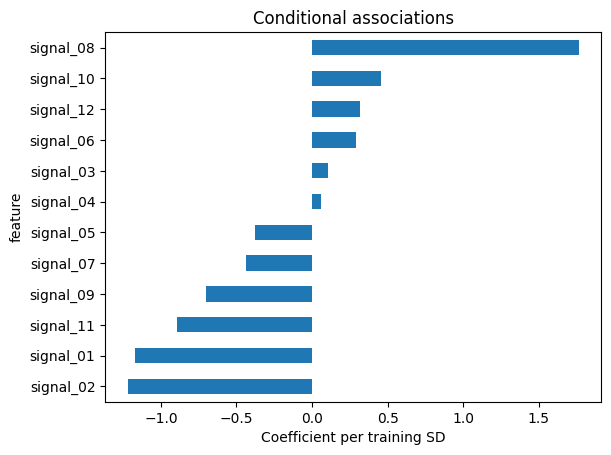

In [14]:
coefficient_model = models[selected_name] if selected_name in models else model_plain
coef = coefficient_model.named_steps['model'].coef_[0]
coef_table = pd.DataFrame({'feature': feature_names, 'coefficient': coef,
                           'odds_multiplier_per_SD': np.exp(coef)})
coef_table = coef_table.iloc[np.argsort(np.abs(coef))[::-1]]
print(coef_table.round(4))
coef_table.set_index('feature')['coefficient'].sort_values().plot.barh()
plt.xlabel('Coefficient per training SD'); plt.title('Conditional associations'); plt.show()

### Task E2 — interpretation and recommendation (7 marks)
Write 200–300 words covering:
- Whether the final model adds value over the majority baseline under the assumed costs.
- Whether validation and test results differ and why this is plausible.
- The strongest positive and negative coefficients, without causal claims.
- At least three limitations: synthetic data, limited positives, static costs, independence assumptions, calibration or representativeness.
- What evidence would be needed before deployment to real payments.

**My response:**

I used the balanced logistic regression model with threshold 0.65. I made this choice using validation data and the given cost formula, not test results. The validation cost was 298 units. On the test set, the cost was 358 units. The majority baseline misses all 39 suspicious payments in the test set, so its cost would be 780 units. This means our selected model is more useful than the baseline under these assumed costs, even though its accuracy is lower.

The test accuracy was about 89.17%, precision was 18.62%, recall was 69.23% and F1 was 29.35%. The validation result was a little better. For example, validation recall was 29 out of 39 (74.36%), while test recall was 27 out of 39 (69.23%). This can happen because the two sets have different payments and only a small number of positive cases. The test ROC-AUC was about 0.863, compared with about 0.891 on validation.

In the balanced model, `signal_08` had the strongest positive coefficient (about +1.76), while `signal_02` had the strongest negative coefficient (about -1.22). This is only an association inside our model. It does not mean these signals cause suspicious activity.

There are important limitations. First, the payments and features are synthetic, not real. Second, there are few suspicious cases, so the metrics can change quite a lot. Third, the costs of 20 and 1 are assumed and may not match reality. Also, the simulation assumes independent rows and does not show how real customer behaviour changes over time. Before using this system, we would need real labelled payments, checks for bias and calibration, tests on later data, and information about the actual cost and workload of investigations.

## F. Master's challenges (20 marks)
Complete **at least one** challenge in depth. Other challenges are optional extensions. For your selected challenge, provide working code, a results table or figure, and a 150–250-word interpretation. Credit: methodological correctness 8, implementation 6, interpretation and limitations 6. A model does not need to improve to earn full marks.

### Challenge F1: Logistic regression from scratch
Implement binary cross-entropy with L2 regularisation and batch gradient descent using NumPy. Use the imputer and scaler fitted on training data only. Add an intercept column and do not penalise the intercept. Specify whether loss uses a mean and define the corresponding regularisation scale. Compare validation log loss and ROC-AUC with the library model. Exact coefficients need not match because regularisation conventions and solvers differ.

### Cell 15 — STUDENT CHALLENGE: stable loss and gradient scaffold
`expit` provides a stable sigmoid. Use `np.logaddexp(0, z) - y*z` for a stable per-observation logistic loss. Derive and implement the gradient. Plot the objective over iterations and explain learning-rate sensitivity.

Validation comparison:
               log_loss  ROC_AUC
from_scratch    0.08717  0.87986
sklearn_plain   0.08791  0.87482
Training loss: first = 0.69315 | last = 0.08917


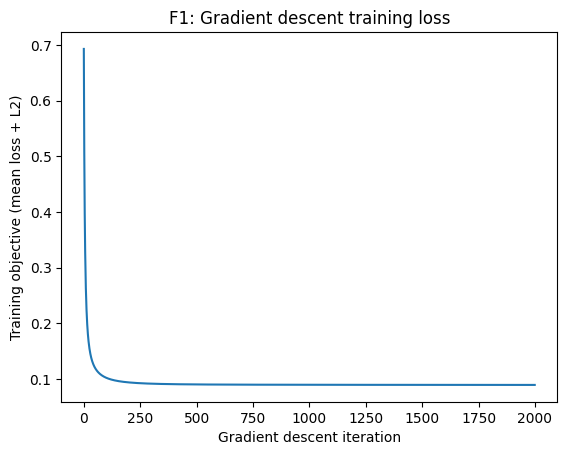

In [15]:
prep = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
Z_train = prep.fit_transform(X_train)
Z_valid = prep.transform(X_valid)
Z_train = np.column_stack([np.ones(len(Z_train)), Z_train])
Z_valid = np.column_stack([np.ones(len(Z_valid)), Z_valid])

def loss_and_gradient(weights, design, target, lam):
    # Average logistic loss plus L2 regularisation (not for intercept).
    scores = design @ weights
    data_loss = np.mean(np.logaddexp(0, scores) - target * scores)
    loss = data_loss + (lam / 2) * np.sum(weights[1:] ** 2)
    probabilities = expit(scores)
    gradient = (design.T @ (probabilities - target)) / len(target)
    gradient[1:] += lam * weights[1:]
    return loss, gradient

# Same approximate regularisation convention as plain sklearn (C=1).
lam = 1 / (len(y_train) * 1.0)
learning_rate = 0.5
iterations = 2000
scratch_weights = np.zeros(Z_train.shape[1])
loss_history = []
for step in range(iterations):
    loss, gradient = loss_and_gradient(scratch_weights, Z_train, y_train.to_numpy(), lam)
    loss_history.append(loss)
    scratch_weights = scratch_weights - learning_rate * gradient

scratch_probability = expit(Z_valid @ scratch_weights)
print('Validation comparison:')
print(pd.DataFrame({
    'from_scratch': {'log_loss': log_loss(y_valid, scratch_probability),
                     'ROC_AUC': roc_auc_score(y_valid, scratch_probability)},
    'sklearn_plain': {'log_loss': log_loss(y_valid, p_valid_plain),
                      'ROC_AUC': roc_auc_score(y_valid, p_valid_plain)}
}).T.round(5))
print('Training loss: first =', round(loss_history[0], 5),
      '| last =', round(loss_history[-1], 5))
plt.plot(np.arange(iterations), loss_history)
plt.xlabel('Gradient descent iteration')
plt.ylabel('Training objective (mean loss + L2)')
plt.title('F1: Gradient descent training loss')
plt.show()


**Challenge F1 — my interpretation:**

In F1, I wrote a simple logistic regression model with NumPy instead of using the ready-made training function. The loss is the average binary cross-entropy plus L2 regularisation. I did not add the penalty to the intercept. For the gradient, I used the difference between predicted probabilities and real labels. The imputer and scaler were fitted on training data only.

I used a learning rate of 0.5 and ran 2,000 gradient descent steps. The training objective went down from about 0.693 to 0.089. This is good because the algorithm is learning. The graph also shows that the changes become smaller with time. On validation data, my model got log loss 0.08717 and ROC-AUC 0.87986. The scikit-learn plain model got log loss 0.08791 and ROC-AUC 0.87482. The numbers are close, so my implementation seems reasonable.

The learning rate is important. A very small value makes training slow. A very large value can make the loss jump around instead of going down. This model still has limitations: the data are synthetic and the exact coefficients can differ from scikit-learn because solvers and stopping rules are not identical.

### Challenge F2: Regularisation and nested selection
Use training-only stratified five-fold cross-validation to compare C in `[0.001, 0.01, 0.1, 1, 10, 100]`. Fit the entire pipeline inside each fold. Report mean and SD of ROC-AUC and average precision. Use the validation partition for your final model/threshold decision.

**Advanced:** design an outer CV loop that estimates the entire model-selection procedure. Explain why selecting C and reporting performance on the same folds can be optimistic. Do not re-use test results to decide whether to include this challenge in the final model.

### Cell 16 — STUDENT CHALLENGE: training-only tuning scaffold
Create a new pipeline per candidate and calculate scores across training folds. Fill `tuning_results` with one row per C.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
C_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
# I chose Challenge F2. Try different C values using training data only.
from sklearn.model_selection import cross_validate
result_rows = []
for C in C_values:
    fold_scores = cross_validate(make_pipeline(C=C), X_train, y_train,
                                 cv=cv,
                                 scoring={'roc_auc': 'roc_auc',
                                          'average_precision': 'average_precision'})
    result_rows.append({'C': C,
                        'ROC_AUC_mean': fold_scores['test_roc_auc'].mean(),
                        'ROC_AUC_SD': fold_scores['test_roc_auc'].std(),
                        'AP_mean': fold_scores['test_average_precision'].mean(),
                        'AP_SD': fold_scores['test_average_precision'].std()})
tuning_results = pd.DataFrame(result_rows)
# Hint: sklearn.model_selection.cross_validate accepts a pipeline and scoring dictionary.
if tuning_results is None:
    print('Challenge F2 pending: evaluate C using training folds only.')
else:
    print(tuning_results)
# Extra check: 3-fold outer CV with 3-fold inner selection, training data only.
from sklearn.model_selection import cross_val_score
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 1)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 2)
nested_rows = []
for outer_fold, (train_idx, holdout_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_part, y_part = X_train.iloc[train_idx], y_train.iloc[train_idx]
    best_c, best_score = None, -1
    for C in C_values:
        score = cross_val_score(make_pipeline(C=C), X_part, y_part,
                                cv=inner_cv, scoring='roc_auc').mean()
        if score > best_score:
            best_score, best_c = score, C
    outer_model = make_pipeline(C=best_c)
    outer_model.fit(X_part, y_part)
    outer_probability = outer_model.predict_proba(X_train.iloc[holdout_idx])[:, 1]
    nested_rows.append({'outer_fold': outer_fold, 'chosen_C': best_c,
                        'outer_ROC_AUC': roc_auc_score(y_train.iloc[holdout_idx], outer_probability)})
nested_results = pd.DataFrame(nested_rows)
print('Outer-fold evaluation (training partition only):')
print(nested_results.round(4))
print('Outer ROC-AUC mean:', round(nested_results['outer_ROC_AUC'].mean(), 4))


         C  ROC_AUC_mean  ROC_AUC_SD   AP_mean     AP_SD
0    0.001      0.819704    0.072034  0.471360  0.084928
1    0.010      0.848125    0.068658  0.533851  0.084319
2    0.100      0.863160    0.063445  0.550501  0.087724
3    1.000      0.861872    0.057915  0.543998  0.093015
4   10.000      0.861777    0.055979  0.540087  0.091816
5  100.000      0.861462    0.055727  0.539133  0.092101
Outer-fold evaluation (training partition only):
   outer_fold  chosen_C  outer_ROC_AUC
0           1       0.1         0.8864
1           2       0.1         0.8857
2           3       0.1         0.7874
Outer ROC-AUC mean: 0.8532


**Challenge F2 — my interpretation:**

For this challenge, I compared six values of `C` by using five-fold cross-validation on the training set. Every fold fits the whole pipeline again, so imputation and scaling use only the training part of that fold. I checked ROC-AUC and average precision (AP). I reported the average score and standard deviation (SD) because results can be different across folds.

The model with `C = 0.1` had the highest mean ROC-AUC, about 0.863, and the highest mean AP, about 0.551. With `C = 0.001`, both scores were lower (ROC-AUC about 0.820 and AP about 0.471). When `C` increased to 1, 10 and 100, performance did not improve. It looks like very strong regularisation makes this model too simple, but weaker regularisation does not always help.

For example, at `C = 0.1`, the ROC-AUC SD was about 0.063 and the AP SD was about 0.088. We have few positive payments, which may explain why the scores move between folds. A limitation is that these are only synthetic data. Also, choosing the best `C` and reporting that same cross-validation score can give an optimistic impression. I also used three-fold outer cross-validation to check this. Its mean ROC-AUC was 0.8532, a little lower than the selected inner-CV result. That is one reason not to report only the best tuning score. I kept the final balanced model and threshold unchanged, so this extra comparison did not use test results to make a new decision.

### Challenge F3: Calibration versus discrimination
On validation data, compare Brier score, log loss and reliability curves for plain and balanced models. Explain how models can rank cases well but produce distorted probabilities. If you fit a calibrator, fit it using training-only cross-validation or a separate calibration subset. Do not fit and evaluate calibration on the same labels.

### Cell 17 — DEMONSTRATION supporting F3: validation calibration
This cell plots equal-frequency reliability bins and reports proper scoring rules. Curves based on few positives are uncertain. A Brier score combines several aspects of performance and should not be described as a pure calibration measure.

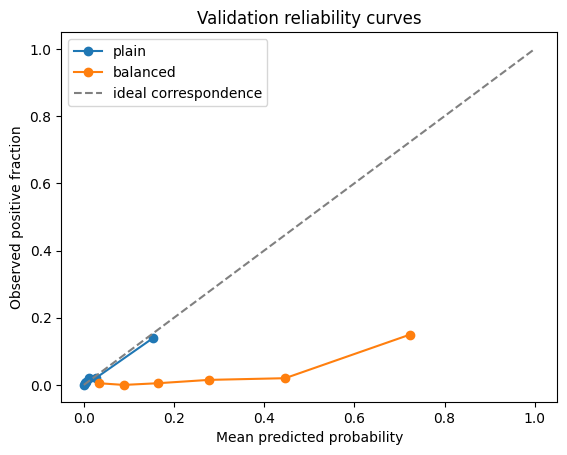

      model    Brier  log_loss
0     plain  0.01958  0.087905
1  balanced  0.12763  0.399370
Validation calibration and ranking (smaller Brier/log loss is better):
              model  Brier  log_loss  ROC_AUC  average_precision
              plain 0.0196    0.0879   0.8748             0.5764
           balanced 0.1276    0.3994   0.8906             0.5187
balanced_calibrated 0.0217    0.0914   0.8906             0.5201


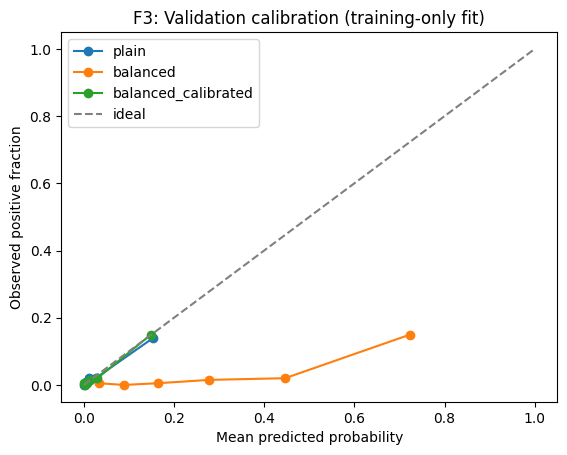

In [17]:
calibration_rows = []
for name, probability in valid_probabilities.items():
    observed, predicted = calibration_curve(y_valid, probability, n_bins=6, strategy='quantile')
    plt.plot(predicted, observed, marker='o', label=name)
    calibration_rows.append({'model': name, 'Brier': brier_score_loss(y_valid, probability),
                             'log_loss': log_loss(y_valid, probability)})
plt.plot([0, 1], [0, 1], '--', color='grey', label='ideal correspondence')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed positive fraction')
plt.title('Validation reliability curves'); plt.legend(); plt.show()
print(pd.DataFrame(calibration_rows))
# Fit a calibrator only on training folds. Validation is used to compare results.
from sklearn.calibration import CalibratedClassifierCV
calibrated_balanced = CalibratedClassifierCV(
    estimator=make_pipeline(class_weight='balanced'),
    method='sigmoid',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED))
calibrated_balanced.fit(X_train, y_train)
p_valid_calibrated = calibrated_balanced.predict_proba(X_valid)[:, 1]

calibration_comparison = pd.DataFrame([
    {'model': name,
     'Brier': brier_score_loss(y_valid, probability),
     'log_loss': log_loss(y_valid, probability),
     'ROC_AUC': roc_auc_score(y_valid, probability),
     'average_precision': average_precision_score(y_valid, probability)}
    for name, probability in {
        'plain': p_valid_plain,
        'balanced': p_valid_balanced,
        'balanced_calibrated': p_valid_calibrated}.items()])
print('Validation calibration and ranking (smaller Brier/log loss is better):')
print(calibration_comparison.round(4).to_string(index=False))

plt.figure()
for name, probs in [('plain', p_valid_plain),
                    ('balanced', p_valid_balanced),
                    ('balanced_calibrated', p_valid_calibrated)]:
    obs, pred = calibration_curve(y_valid, probs, n_bins=6, strategy='quantile')
    plt.plot(pred, obs, marker='o', label=name)
plt.plot([0, 1], [0, 1], '--', color='grey', label='ideal')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed positive fraction')
plt.title('F3: Validation calibration (training-only fit)')
plt.legend()
plt.show()


**Challenge F3 — my interpretation:**

In F3, I checked if the predicted probabilities match the real number of positive payments. I used Brier score, log loss and reliability curves. Smaller Brier score and log loss are better. On validation data, the plain model had a Brier score of 0.0196 and log loss of 0.0879. The balanced model had much higher values, 0.1276 and 0.3994. So its probabilities were not as useful, even though its ROC-AUC was slightly better (0.8906 against 0.8748).

I also fitted a calibrated balanced model. I trained its calibrator by cross-validation using only the training set. I did not train it on the validation labels. After calibration, its Brier score improved to 0.0217 and log loss to 0.0914. This is a big improvement, but the plain model still had slightly better probability scores here.

I learned that ranking payments and estimating probabilities are not the same task. A model can put risky cases higher on the list but still give probabilities that are too large. A limitation is that the validation set has only 39 positive cases, so the reliability curves are not very stable. Also, Brier score is not only a calibration measure.

### Challenge F4: Bootstrap uncertainty
After freezing your rule, bootstrap the final test observations 2,000 times and calculate percentile 95% intervals for recall, F1 and ROC-AUC. Handle any single-class resamples explicitly. Compare ordinary and class-stratified resampling and explain their different conditioning assumptions. State that these intervals condition on the fitted model and do not capture all training/selection variability.

### Cell 18 — STUDENT CHALLENGE: uncertainty scaffold
Complete `bootstrap_rows` using resampling indices. Keep each observation's label, probability and decision paired. Do not refit the model or choose a new threshold within this analysis. Synthetic observations are independent; repeated-patient data would require group-aware resampling.

In [18]:
# Bootstrap the already frozen test predictions (no refitting or new threshold).
bootstrap_rows = []
if p_test is None:
    print('Complete and freeze the final evaluation before Challenge F4.')
else:
    test_labels = y_test.to_numpy()
    test_probs = np.asarray(p_test)
    test_decisions = (test_probs >= chosen_threshold).astype(int)
    n = len(test_labels)
    positive_idx = np.flatnonzero(test_labels == 1)
    negative_idx = np.flatnonzero(test_labels == 0)
    bootstrap_rng = np.random.default_rng(SEED + 400)
    single_class_counts = {'ordinary': 0, 'stratified': 0}
    for method in ['ordinary', 'stratified']:
        for repeat in range(2000):
            if method == 'ordinary':
                idx = bootstrap_rng.choice(n, size=n, replace=True)
            else:
                idx = np.concatenate([
                    bootstrap_rng.choice(positive_idx, size=len(positive_idx), replace=True),
                    bootstrap_rng.choice(negative_idx, size=len(negative_idx), replace=True)])
            yt = test_labels[idx]
            pr = test_probs[idx]
            predictions = test_decisions[idx]
            if len(np.unique(yt)) < 2:
                single_class_counts[method] += 1
                auc = np.nan  # ROC-AUC cannot be calculated with one class.
            else:
                auc = roc_auc_score(yt, pr)
            bootstrap_rows.append({'method': method,
                                   'recall': recall_score(yt, predictions, zero_division=0),
                                   'F1': f1_score(yt, predictions, zero_division=0),
                                   'ROC_AUC': auc})
    bootstrap_frame = pd.DataFrame(bootstrap_rows)
    print('Number of bootstrap samples per method: 2000')
    print('Single-class samples (ROC-AUC set to NaN):', single_class_counts)
    summary = bootstrap_frame.groupby('method')[['recall', 'F1', 'ROC_AUC']].agg(
        ['mean', lambda values: values.quantile(0.025),
         lambda values: values.quantile(0.975)])
    summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
    summary.columns = [col.replace('<lambda_0>', 'lower_95').replace('<lambda_1>', 'upper_95')
                       for col in summary.columns]
    print(summary.round(4).to_string())


Number of bootstrap samples per method: 2000
Single-class samples (ROC-AUC set to NaN): {'ordinary': 0, 'stratified': 0}
            recall_mean  recall_lower_95  recall_upper_95  F1_mean  F1_lower_95  F1_upper_95  ROC_AUC_mean  ROC_AUC_lower_95  ROC_AUC_upper_95
method                                                                                                                                        
ordinary         0.6922           0.5429           0.8333   0.2925       0.2060       0.3767        0.8624            0.7745            0.9329
stratified       0.6935           0.5385           0.8462   0.2942       0.2336       0.3575        0.8624            0.7795            0.9322


**Challenge F4 — my interpretation:**

In F4, I used bootstrap resampling to see how much the final test results might change if we had another sample. I kept the selected model and threshold 0.65 fixed. I did not train a new model. I made 2,000 ordinary bootstrap samples and 2,000 stratified bootstrap samples. For each sample, I calculated recall, F1 and ROC-AUC.

With ordinary bootstrap, the 95% interval for recall was about 0.543–0.833, for F1 it was 0.206–0.377, and for ROC-AUC it was 0.775–0.933. With stratified bootstrap, the intervals were about 0.538–0.846 for recall, 0.234–0.358 for F1 and 0.780–0.932 for ROC-AUC. No samples contained only one class in this run. The code would mark ROC-AUC as missing if that happened.

Ordinary bootstrap lets the number of positive cases change. Stratified bootstrap keeps the original positive and negative counts. That is why the intervals are a bit different. The main lesson is that one test score is not an exact number for future performance. These intervals only show uncertainty from resampling the test observations. They do not include uncertainty from choosing or training the model.

### Challenge F5: Multiclass logistic regression
Use the built-in Iris dataset. Create stratified train/validation/test partitions, scale within a pipeline, and fit logistic regression. Interpret the 3-column probability matrix using `classes_`. Compare macro-F1 and weighted-F1, and show a 3 × 3 confusion matrix. Explain why accuracy and weighted averages can hide poor minority-class performance.

### Cell 19 — STUDENT CHALLENGE: offline multiclass starter
This cell loads measurements and species labels. Build your own split and model below. Use a compatible multinomial solver, such as `lbfgs`, and avoid hard-coding class-column meanings.

Iris: (150, 4) | species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Train / validation / test: 90 30 30
Probability columns match classes_: [0 1 2] [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
   setosa  versicolor  virginica
0   0.043       0.773      0.184
1   0.959       0.041      0.000
2   0.023       0.609      0.368
3   0.977       0.023      0.000
     split  accuracy  macro_F1  weighted_F1
validation    0.9333    0.9333       0.9333
      test    0.9333    0.9327       0.9327
Test classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



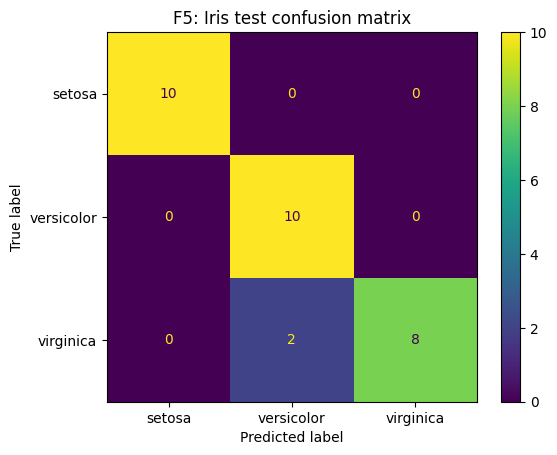

In [19]:
iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target
print('Iris:', X_iris.shape, '| species:', list(iris.target_names))

X_i_train, X_i_rest, y_i_train, y_i_rest = train_test_split(
    X_iris, y_iris, test_size=0.40, stratify=y_iris, random_state=SEED)
X_i_valid, X_i_test, y_i_valid, y_i_test = train_test_split(
    X_i_rest, y_i_rest, test_size=0.50, stratify=y_i_rest, random_state=SEED)

iris_model = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(solver='lbfgs', max_iter=3000, random_state=SEED))])
iris_model.fit(X_i_train, y_i_train)
print('Train / validation / test:', len(X_i_train), len(X_i_valid), len(X_i_test))

iris_classes = iris_model.named_steps['model'].classes_
probability_columns = [iris.target_names[class_id] for class_id in iris_classes]
iris_probabilities = iris_model.predict_proba(X_i_test)
print('Probability columns match classes_:', iris_classes, probability_columns)
print(pd.DataFrame(iris_probabilities[:4], columns=probability_columns).round(3))

iris_rows = []
for split_name, X_part, y_part in [('validation', X_i_valid, y_i_valid),
                                   ('test', X_i_test, y_i_test)]:
    iris_pred = iris_model.predict(X_part)
    iris_rows.append({'split': split_name,
                      'accuracy': accuracy_score(y_part, iris_pred),
                      'macro_F1': f1_score(y_part, iris_pred, average='macro'),
                      'weighted_F1': f1_score(y_part, iris_pred, average='weighted')})
print(pd.DataFrame(iris_rows).round(4).to_string(index=False))
print('Test classification report:')
print(classification_report(y_i_test, iris_model.predict(X_i_test),
                            target_names=probability_columns, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_i_test, iris_model.predict(X_i_test),
                                       labels=iris_classes,
                                       display_labels=probability_columns)
plt.title('F5: Iris test confusion matrix')
plt.show()


**Challenge F5 — my interpretation:**

In F5, I used logistic regression to classify three Iris flower species instead of only two classes. I split 150 rows into 90 training, 30 validation and 30 test rows. The splits were stratified, so each species was represented. I used a pipeline with StandardScaler and LogisticRegression. The scaler was fitted only on the training data.

The model returned a probability matrix with three columns. I used `classes_` to check the correct order: setosa, versicolor and virginica. For each flower, the three probabilities show how likely the model thinks each class is. On the test set, accuracy was 0.9333. Macro-F1 and weighted-F1 were both about 0.9327. The confusion matrix shows two mistakes: both were virginica flowers predicted as versicolor. Setosa had recall 1.00, while virginica had recall 0.80.

Macro-F1 gives each class equal importance. Weighted-F1 gives more weight to classes with more examples. They are similar in this experiment because each class has 10 test examples. But with a very small minority class, accuracy and weighted scores might look high even when that class is predicted badly. This dataset is small, so results can change with a different split.

### Challenge F6: Distribution shift and stress testing
Freeze a model using the original training and validation data. Construct a separate synthetic stress set with `make_classification`, using a different seed and changing class prevalence or separation. Report performance without retuning. Explain that a different generator seed may also change the underlying feature–label relationship, so this experiment does not isolate pure prevalence shift.

For a more controlled experiment, reweight or subsample cases by class from a separately reserved evaluation population while holding the conditional feature distributions approximately fixed. Discuss what your design can and cannot establish. Never choose a model because it wins on the stress set.

### Cell 20 — STUDENT CHALLENGE: stress-test plan
Document your change first, then implement it. Give feature columns exactly the training names and use the already fitted pipeline without refitting the imputer or scaler.

In [20]:
# First state the design. The test rule remains frozen.
stress_plan = ("I keep the fitted balanced logistic regression and the same threshold. "
               "I generate new synthetic observations with 10% positives and a smaller "
               "class separation (0.8 instead of 1.3), using a different seed. "
               "I expect the results to change, but the new seed also changes the "
               "feature-label relationship. This is not a clean prevalence-only test.")
print('Stress test plan:', stress_plan)

X_stress_array, y_stress = make_classification(
    n_samples=1200, n_features=12, n_informative=7, n_redundant=3,
    n_repeated=0, n_clusters_per_class=2, weights=[0.90, 0.10],
    class_sep=0.8, flip_y=0.005, random_state=SEED + 100)
X_stress = pd.DataFrame(X_stress_array, columns=feature_names)
stress_rng = np.random.default_rng(SEED + 101)
X_stress = X_stress.mask(stress_rng.random(X_stress.shape) < 0.025)

# Predict without refitting, retuning or learning from the stress set.
stress_probabilities = final_model.predict_proba(X_stress)[:, 1]
stress_predictions = (stress_probabilities >= chosen_threshold).astype(int)
stress_results = []
for name, actual, probs in [('original_test', y_test, p_test),
                            ('stress_set', y_stress, stress_probabilities)]:
    predictions = (np.asarray(probs) >= chosen_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predictions, labels=[0, 1]).ravel()
    stress_results.append({'dataset': name, 'positive_rate': np.mean(actual),
                           'precision': precision_score(actual, predictions, zero_division=0),
                           'recall': recall_score(actual, predictions, zero_division=0),
                           'F1': f1_score(actual, predictions, zero_division=0),
                           'ROC_AUC': roc_auc_score(actual, probs),
                           'cost_20FN_plus_FP': 20 * fn + fp})
stress_results = pd.DataFrame(stress_results)
print('Frozen model:', selected_name, '| frozen threshold:', chosen_threshold)
print(stress_results.round(4).to_string(index=False))

# More controlled illustration: change prevalence by reweighting the already reserved
# test cases, without changing their observed features or model scores.
target_prevalence = 0.10
original_prevalence = y_test.mean()
class_weights = np.where(y_test.to_numpy() == 1,
                         target_prevalence / original_prevalence,
                         (1 - target_prevalence) / (1 - original_prevalence))
reweight_result = pd.DataFrame([
    {'scenario': 'observed_test_prevalence',
     'positive_rate': original_prevalence,
     'precision': precision_score(y_test, pred_test, zero_division=0),
     'recall': recall_score(y_test, pred_test, zero_division=0)},
    {'scenario': 'reweighted_to_10_percent',
     'positive_rate': target_prevalence,
     'precision': precision_score(y_test, pred_test, sample_weight=class_weights, zero_division=0),
     'recall': recall_score(y_test, pred_test, sample_weight=class_weights, zero_division=0)}])
print('Controlled prevalence reweighting of reserved test observations (no model changes):')
print(reweight_result.round(4).to_string(index=False))


Stress test plan: I keep the fitted balanced logistic regression and the same threshold. I generate new synthetic observations with 10% positives and a smaller class separation (0.8 instead of 1.3), using a different seed. I expect the results to change, but the new seed also changes the feature-label relationship. This is not a clean prevalence-only test.
Frozen model: balanced | frozen threshold: 0.65
      dataset  positive_rate  precision  recall     F1  ROC_AUC  cost_20FN_plus_FP
original_test         0.0325     0.1862  0.6923 0.2935   0.8627                358
   stress_set         0.1017     0.1682  0.5820 0.2610   0.6989               1371
Controlled prevalence reweighting of reserved test observations (no model changes):
                scenario  positive_rate  precision  recall
observed_test_prevalence         0.0325     0.1862  0.6923
reweighted_to_10_percent         0.1000     0.4308  0.6923


**Challenge F6 — my interpretation:**

In F6, I checked what happens when the data are different from the training data. I kept the balanced model and threshold 0.65 exactly as before. I created a new synthetic stress set with about 10% positive cases and smaller class separation. I also used a new random seed. I did not retrain the model or pick a better threshold based on this set.

On the original test set, ROC-AUC was 0.8627, recall was 0.6923 and F1 was 0.2935. On the stress set, ROC-AUC dropped to 0.6989, recall to 0.5820 and F1 to 0.2610. The cost also increased from 358 to 1,371 units, although the groups have different positive rates, so this difference is not caused by one factor alone.

For a more controlled example, I reweighted the original reserved test cases to represent 10% positives. The precision increased from 0.1862 to 0.4308, but recall stayed at 0.6923. This helps show how prevalence can change precision even when the model is unchanged. A limitation is that the new synthetic seed can change the feature-label relationship too. Therefore this stress test cannot separate prevalence shift from other changes.

## Final reflection
Answer in 150–250 words:
1. Which metric changed your judgement most compared with accuracy alone?
2. Which decision did you make using validation data, and why must it precede test evaluation?
3. What did your selected master's challenge reveal that the basic model score did not?
4. What would you change if rows represented repeated customers, patients or daily observations from the same device?

**My response:**

The metric that changed my opinion most was recall. At first, the majority baseline looked good because it had 96.75% accuracy. But it did not find any suspicious payments. The confusion matrix and recall made this problem clear. F1 was also useful because a model with high recall can create too many false alerts.

Using validation data, I compared the plain and balanced models and calculated the cost of false positives and false negatives at different thresholds. I selected the balanced model with threshold 0.65 because it had the lowest cost under the given assumptions. This choice must happen before testing. If I look at test results and keep changing my model, the test set is no longer a fair check.

The F challenges showed me different problems. In F1, I built gradient descent myself. In F2, I compared regularisation strengths and noticed that cross-validation results change. F3 showed why good ranking does not always mean good probabilities. F4 showed that recall and F1 have wide uncertainty intervals. In F5, one flower species had lower recall than the others. In F6, performance dropped on changed data. These experiments showed me why one accuracy number cannot describe everything about a model.

If the rows came from repeated customers or patients, I would split by customer or patient so that the same person was not in both training and test sets. For daily device observations, I would consider a time-based split. I would also check whether performance changes over time.

## Submission checklist
- [x] Name and student ID completed.
- [x] Tasks A–E contain code, outputs and written interpretations.
- [x] All six master's challenges include methods, results and limitations (F1–F6).
- [x] Model and threshold selection use no test results.
- [x] No placeholder remains in a task claimed as complete; all challenges are completed.
- [x] Notebook runs from a fresh kernel in order without hidden state.
- [x] Figures have titles and labelled axes.
- [x] Sources and any AI assistance are acknowledged according to course policy.

**Conceptual references:** Lecture 5, *Classification Basics — Logistic Regression for Predicting a Class*; scikit-learn documentation for pipelines, logistic regression, model evaluation and probability calibration. No claim of real-world financial or clinical performance follows from these synthetic experiments.